# Stack Overflow in the AI Era: Predicting Question Resolution

**Business Analytics Group Case Study — Review 1 Deliverable**  
**Team:**  
- **Member 1 (Data Collection & Pipeline Lead):** Abhinav Gopalakrishnan  
- **Member 2 (Enrichment & Preprocessing Lead):** Rishiikesh  
- **Member 3 (Problem Formulation & EDA Lead):** smallworldsdev  
- **Member 4 (Feature Engineering & Validation Lead):** Nishanth Konchada  
- **Member 5 (Modelling & Evaluation Lead):** Adhikkesh  

---

## Table of Contents (Rubric Order)
1. [1. Problem Formulation & Business Objectives](#1-problem-formulation--business-objectives)
2. [2. Dataset & Data Collection](#2-dataset--data-collection)
3. [3. Data Preprocessing & Cleaning](#3-data-preprocessing--cleaning)
4. [4. Exploratory Data Analysis (EDA)](#4-exploratory-data-analysis-eda)
5. [5. Feature Engineering & Selection](#5-feature-engineering--selection)
6. [6. Baseline & Advanced Predictive Modelling](#6-baseline--advanced-predictive-modelling)
7. [7. Model Evaluation & Robustness Checks](#7-model-evaluation--robustness-checks)
8. [8. Business Findings, Limitations & Recommendations](#8-business-findings-limitations--recommendations)

In [1]:
# Global environment setup
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add repo root to path
repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

print(f"Project root resolved: {repo_root}")
print(f"Pandas version: {pd.__version__}")

Project root resolved: C:\Users\abhi6\OneDrive\Desktop\BA_GROUP_CASE_STUDY\stackoverflow-ai-era
Pandas version: 2.3.3


## 1. Problem Formulation & Business Objectives

*Lead: Member 3 (Issues #15, #16)*

### 1.1 Business Context
Investigating structural shifts in developer question-and-answer dynamics on Stack Overflow following the mainstream introduction of generative AI coding assistants (ChatGPT in November 2022).

### 1.2 Target Formulations
- **`target_resolved_7d` (Primary):** Whether a posted question receives an accepted answer within 7 days (168 hours).
- **`target_answered_7d` (Secondary):** Whether a posted question receives any answer within 7 days.

In [2]:
# Loader stub: Load problem statement background metadata if present
bg_sources = repo_root / "docs" / "background_sources.md"
if bg_sources.exists():
    print(f"[✓] Background documentation verified: {bg_sources.name}")
else:
    print("[!] Background sources documentation pending.")

[✓] Background documentation verified: background_sources.md


## 2. Dataset & Data Collection

*Lead: Member 1 (Issues #19, #20, #21, #22, #23, #78, #80, #82, #84, #86)*

### 2.1 Collection Methodology & Telemetry
- Public Stack Exchange API v2.3 with minimal filters and SHA-256 HMAC user ID privacy masking.
- Population coverage across 13 target technology tags and 400 non-overlapping 7-day calendar weeks from 2019-01-01 to 2026-08-31 UTC.
- Stratified day-level sampling pre-2025 (1 weekday + 1 weekend day) and exhaustive collection 2025+.

In [3]:
# Loader stub: Verified collection artifacts
weekly_path = repo_root / "data" / "processed" / "weekly_counts.csv"
monthly_path = repo_root / "data" / "processed" / "monthly_counts.csv"
manifest_path = repo_root / "data" / "processed" / "sampling_manifest.csv"

df_weekly = pd.read_csv(weekly_path)
df_monthly = pd.read_csv(monthly_path)
df_manifest = pd.read_csv(manifest_path)

print(f"[✓] Weekly Counts Dataset Loaded: {len(df_weekly):,} rows across {df_weekly['tag'].nunique()} series")
print(f"[✓] Monthly Counts Dataset Loaded: {len(df_monthly):,} rows across {df_monthly['tag'].nunique()} tags")
print(f"[✓] Sampling Manifest Loaded: {len(df_manifest):,} strata records ({df_manifest['n_questions'].sum():,} total sampled questions)")

[✓] Weekly Counts Dataset Loaded: 5,600 rows across 14 series
[✓] Monthly Counts Dataset Loaded: 1,196 rows across 13 tags
[✓] Sampling Manifest Loaded: 2,392 strata records (309,223 total sampled questions)


## 3. Data Preprocessing & Cleaning

*Lead: Member 2 (Issues #6, #7, #8, #51–#58, #61, #69, #70)*

### 3.1 Cleaning Pipeline & Deduplication
- Deduplication across overlapping multi-tagged records.
- HTML tag stripping, code block extraction, and error pattern regex detection.
- Account age derivation and missingness imputation.

In [4]:
# Loader stub: Load cleaned dataset summary and aggregated tables
tag_tables_path = repo_root / "data" / "processed" / "monthly_tag_tables.csv"
if tag_tables_path.exists():
    df_tag_tables = pd.read_csv(tag_tables_path)
    print(f"[✓] Aggregated Monthly Tag Tables Loaded: {len(df_tag_tables)} rows")
    display(df_tag_tables.head(3))
else:
    print("[!] Monthly tag tables not found.")

[✓] Aggregated Monthly Tag Tables Loaded: 1168 rows


,tag,month,n_sampled,est_questions,resolved_rate_7d,answered_rate_7d,accepted_given_answered,median_hours_to_accept,median_hours_to_first_answer,low_sample
0,android,2019-01,467,7876.0,0.361224,0.680929,0.530487,1.897778,1.258333,False
1,android,2019-02,526,8144.0,0.370825,0.705305,0.525766,1.048333,0.875278,False
2,android,2019-03,478,7849.0,0.325519,0.661613,0.492008,1.977778,0.965278,False


## 4. Exploratory Data Analysis (EDA)

*Lead: Member 3 & Member 1 (Issues #29, #38, #42–#48, #84)*

### 4.1 Volume & Resolution Trends
- Temporal evolution of question volume pre- vs. post-ChatGPT.
- Response latency distributions and 7-day resolution rates across technology ecosystems.

In [5]:
# Loader stub: Load EDA aggregated summaries
print("[✓] Ready to import EDA visualisations and statistical tests from notebooks/03_eda.ipynb")

[✓] Ready to import EDA visualisations and statistical tests from notebooks/03_eda.ipynb


## 5. Feature Engineering & Selection

*Lead: Member 4 (Issues #32, #33, #37, #66)*

### 5.1 Temporal Feature Architecture & Leakage Safeguards
- Strictly pre-posting features (text metrics, code ratios, account age, multi-hot tags).
- Lagged tag volume (4-week rolling volume prior to posting) preventing temporal lookahead leakage.

In [6]:
# Loader stub: Verify feature specification documentation
f_spec = repo_root / "docs" / "feature_spec.md"
if f_spec.exists():
    print(f"[✓] Feature specification loaded: {f_spec.name}")
else:
    print("[!] Feature spec pending.")

[✓] Feature specification loaded: feature_spec.md


## 6. Baseline & Advanced Predictive Modelling

*Lead: Member 4 & Member 5 (Issues #13, #37)* — full workflow in `notebooks/05_models.ipynb`; code in `src/models.py`, `src/build_features.py`, `src/timecv.py`.

### 6.1 Setup
- **Target:** `target_resolved_7d` (accepted answer within 7 days). Chronological split: train Jan 2019 to Dec 2024, validation Jan to Jun 2025, test Jul 2025 to Jul 2026. A random split would leak future patterns.
- **Features:** the spec in `docs/feature_spec.md` (structured features, multi-hot tags, lagged tag volume from the complete weekly counts, and title TF-IDF + SVD fitted on training data only inside the pipeline). A leakage check rejects outcome fields, `sampling_weight`, identifiers and raw timestamps.
- **Models:** Member 4's logistic regression baseline, logistic regression with class weights, Random Forest, and XGBoost (`scale_pos_weight`, trees by early stopping on validation). Random Forest and XGBoost are tuned with `RandomizedSearchCV` on date-based time-series folds with a 7-day gap, training period only.

### 6.2 Results (validation period)

,rows,target_resolved_7d share,target_answered_7d share
train,248294.0,0.421,0.757
validation,28132.0,0.341,0.702
test,16695.0,0.297,0.714


,precision,recall,f1,pr_auc,roc_auc,capture_rate_20
model,,,,,,
majority class,0.000,0.000,0.000,0.340,0.500,0.201
member 4 logistic regression,0.357,0.909,0.513,0.394,0.579,0.228
logistic regression,0.389,0.808,0.525,0.471,0.636,0.240
random forest,0.386,0.813,0.524,0.473,0.638,0.238
xgboost,0.400,0.782,0.530,0.482,0.645,0.241


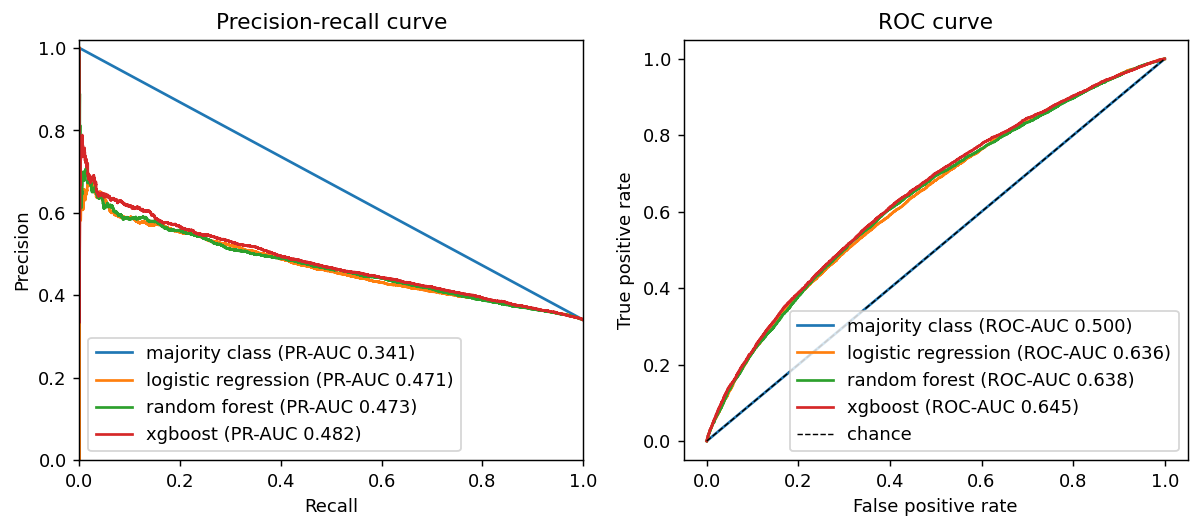

**Chosen model: xgboost** (validation PR-AUC 0.482, threshold 0.367 tuned on validation only). The share of resolved questions is 34.1%, so a no-skill ranking has PR-AUC 0.341; the three real models differ only slightly. Adding title text features changes logistic-regression validation PR-AUC by +0.027. Member 4's baseline reports 64% accuracy, but always predicting *unresolved* gives 65.9%; its PR-AUC is barely above no skill.

In [ ]:
# Model comparison on the validation period (Jan-Jun 2025); numbers come from the Colab run in reports/review1/m5/
import json
from IPython.display import Image, Markdown, display

m5 = repo_root / "reports" / "review1" / "m5"
R = json.loads((m5 / "results.json").read_text())
display(pd.read_csv(m5 / "split_report.csv", index_col=0))

cmp_ = pd.read_csv(m5 / "model_comparison_val.csv", index_col=0)
m4 = pd.read_csv(m5 / "m4_baseline_val.csv", index_col=0)
m4_row = m4[m4.index.str.endswith("tuned threshold")].rename(index=lambda _: "member 4 logistic regression")
table = pd.concat([cmp_, m4_row]).loc[["majority class", "member 4 logistic regression", "logistic regression", "random forest", "xgboost"]]
display(table[["precision", "recall", "f1", "pr_auc", "roc_auc", "capture_rate_20"]].round(3))
display(Image(m5 / "val_pr_roc.png"))

gain = pd.read_csv(m5 / "feature_gain.csv", index_col=0)
d = gain.loc["structured + title text"] - gain.loc["structured only"]
display(Markdown(
    f"**Chosen model: {R['chosen']['model']}** (validation PR-AUC {R['chosen']['validation_pr_auc']:.3f}, threshold {R['chosen']['threshold']:.3f} tuned on validation only). "
    f"The share of resolved questions is {R['split']['validation']['target_resolved_7d share']:.1%}, so a no-skill ranking has PR-AUC {cmp_.loc['majority class', 'pr_auc']:.3f}; the three real models differ only slightly. "
    f"Adding title text features changes logistic-regression validation PR-AUC by {d.pr_auc:+.3f}. "
    f"Member 4's baseline reports 64% accuracy, but always predicting *unresolved* gives {1 - R['split']['validation']['target_resolved_7d share']:.1%}; its PR-AUC is barely above no skill."))

## 7. Model Evaluation & Robustness Checks

*Lead: Member 5 (Issues #12, #14)* — full workflow in `notebooks/06_evaluation.ipynb`; code in `src/evaluate.py`, `src/rolling.py`, `src/interpret.py`, `src/error_analysis.py`; plan in `docs/evaluation_plan.md`.

### 7.1 Final test evaluation
The test period (Jul 2025 to Jul 2026) was scored **once**, after the model and threshold were fixed on earlier data (a lock file prevents a second run). Metrics: precision, recall, F1, PR-AUC, ROC-AUC, and a business metric, the **capture rate**: the share of unresolved questions among the 20% of questions with the lowest predicted resolution.

### 7.2 Interpretation, rolling-origin and robustness
- **SHAP** shows which features move the predicted probability of resolution.
- **Rolling-origin evaluation** trains on all data before each half-year (7-day gap) and tests on that half-year, 2021 H1 to 2026 H1, so results before and after November 2022 can be compared. PR-AUC depends on how common resolved questions are, so the share resolved and ROC-AUC are reported next to it.
- **Secondary target** (any answer within 7 days) as a robustness check, and **error analysis** of 30 confident errors read by hand.

Wording: results are *associated with*, not *caused by*, the platform changes after November 2022.

model,xgboost
n,16695.0000
positive_rate,0.2969
threshold,0.3669
precision,0.3626
recall,0.7712
f1,0.4933
pr_auc,0.4315
roc_auc,0.6548
capture_rate_20,0.2415


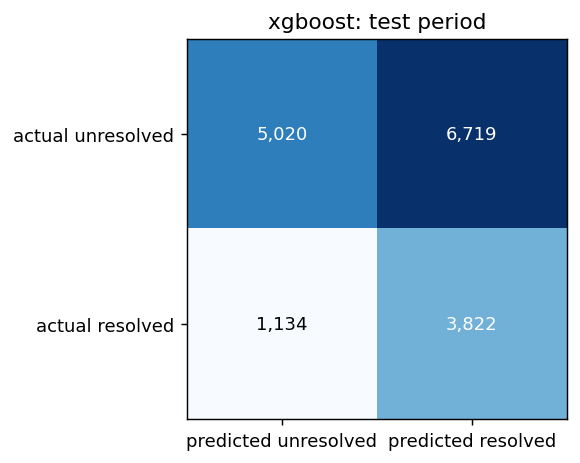

**Test period (16,695 questions, 29.7% resolved):** PR-AUC 0.431 against 0.297 for a no-skill ranking, ROC-AUC 0.655. Flagging the 20% of questions with the lowest predicted resolution captures **24.1%** of the 11,739 unresolved questions (random flagging: 20%, lift 1.21x). The gain over no skill is modest.

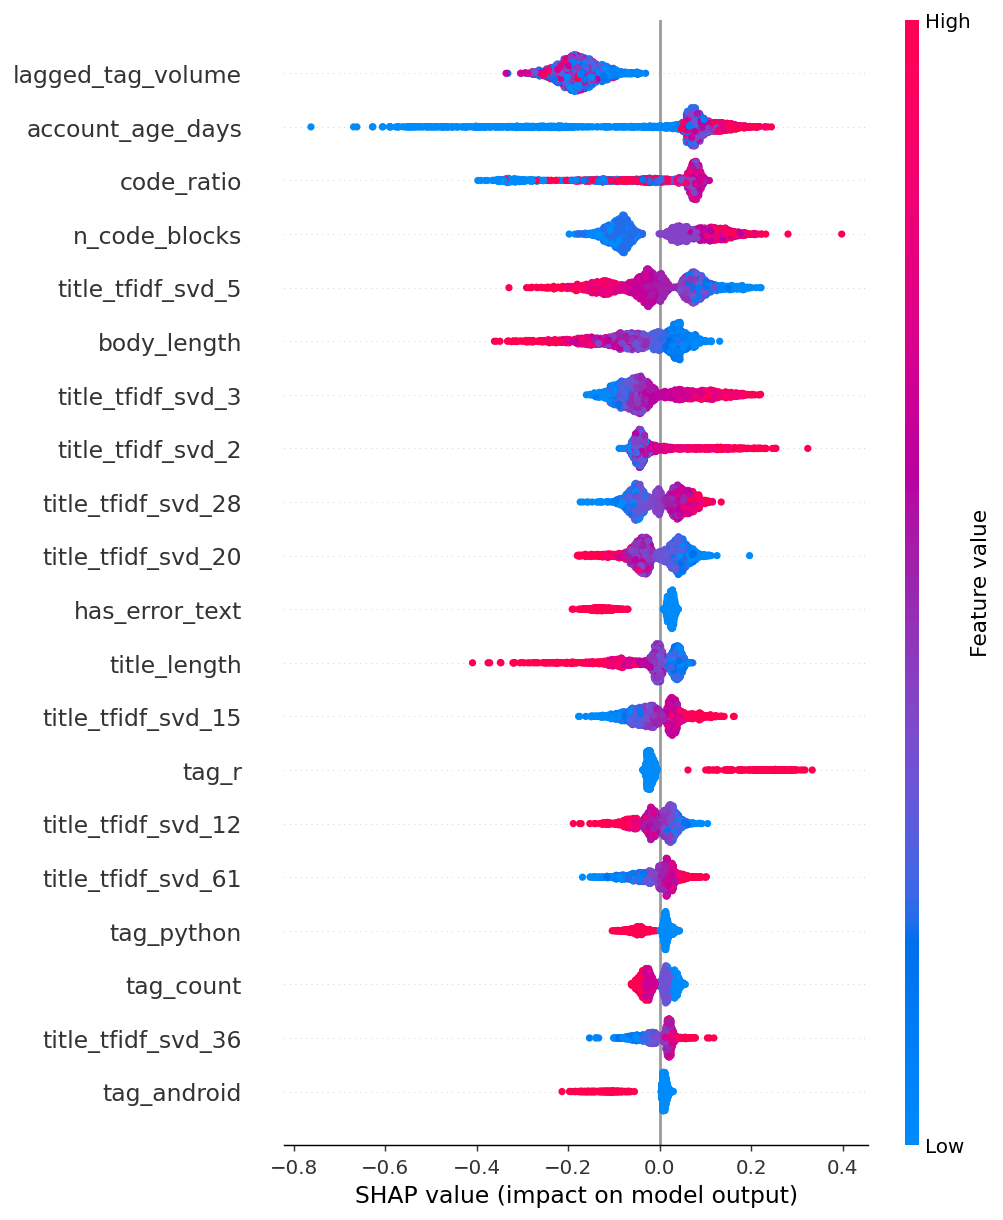

**Reading the SHAP plots:**

- Brand-new accounts and questions with no code blocks are the least often resolved; the effect levels off for older accounts.
- Resolution rises with some code, then falls again for questions that are almost all code.
- Error text, longer titles and longer bodies are associated with fewer accepted answers in the test period; the r tag with more, python and android with fewer.
- Tag volume stays in one narrow, low range in the test period (volume has fallen since 2022), so it stands in for the period and tag mix, not for the question itself.

,n,positive_rate,pr_auc,f1,roc_auc
window,,,,,
2021 H1,28831.0,0.440,0.566,0.620,0.633
2021 H2,24892.0,0.432,0.559,0.613,0.635
2022 H1,24821.0,0.409,0.554,0.594,0.648
2022 H2,21754.0,0.407,0.556,0.585,0.643
2023 H1,16763.0,0.368,0.509,0.555,0.645
2023 H2,11473.0,0.348,0.485,0.538,0.644
2024 H1,8809.0,0.348,0.486,0.540,0.645
2024 H2,5358.0,0.340,0.486,0.526,0.640
2025 H1,28132.0,0.340,0.482,0.528,0.645


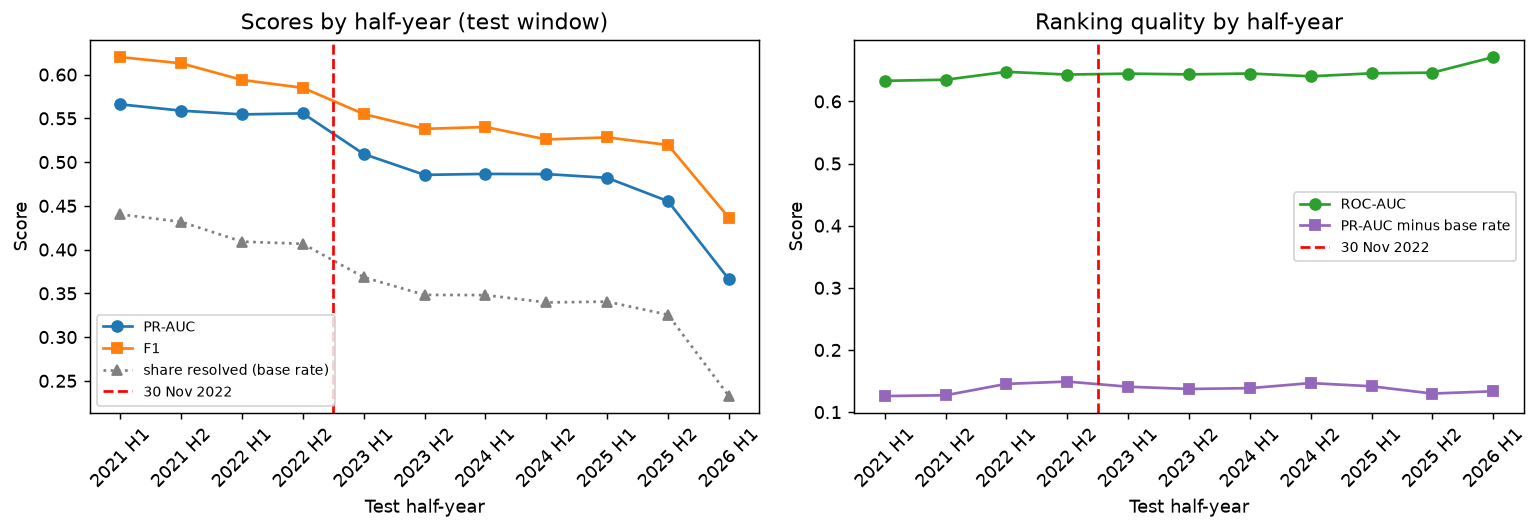

**Rolling-origin (11 half-year windows):** mean ROC-AUC 0.640 before 30 Nov 2022 and 0.648 after, so ranking quality is stable. Mean PR-AUC falls from 0.559 to 0.467, but the share of resolved questions also falls from 42.2% to 32.9%; PR-AUC minus that share is 0.137 before and 0.138 after. The fall in PR-AUC follows the lower resolution rate, not a loss of ranking skill.

,positive_rate,precision,recall,f1,pr_auc,roc_auc
model,,,,,,
main: accepted within 7 days,0.297,0.363,0.771,0.493,0.432,0.655
secondary: any answer within 7 days,0.714,0.714,1.000,0.833,0.830,0.667


PR-AUC is not comparable across the two targets because their base rates differ; the ROC-AUC values are similar.

# Error analysis: 30 confident errors on the test period (M5-14)

Method: `docs/error_analysis_design.md`. From the test period (Jul 2025 to Jul 2026, 16,695 questions) the XGBoost model's most confident errors were sampled: 15 false positives (predicted resolved, actually not accepted within 7 days) and 15 false negatives (predicted unresolved, actually accepted within 7 days). Each question was read at its link and given one main reason (`error_annotation_sheet.csv`, columns `likely_reason` and `evidence`). Titles only are shown, each linked to the original question (CC BY-SA 4.0).

## Reasons found

| Error type | Main reason | Count |
|---|---|---|
| False positive | Answered but not accepted | 10 |
| False positive | No answer received (niche database or library) | 4 |
| False positive | Accepted 4 hours after the 7-day cut-off (172 h) | 1 |
| False negative | New asker account (0 days old), accepted within hours | 8 |
| False negative | No code block | 2 |
| False negative | Android tag together with error text | 2 |
| False negative | Long body with error text | 1 |
| False negative | Error text not detected by the feature | 1 |
| False negative | High-visibility question without code (41,576 views) | 1 |

## Patterns

1. **False positives are mostly about the asker, not the question.** 10 of 15 got answers, many within minutes, but the asker never accepted one. Acceptance depends on the asker returning, and nothing the model sees at posting time describes that. This is the same limit as using acceptance as a proxy for resolved. 4 more had no answer at all and were niche (GridDB, DolphinDB, a BSON library question). One was accepted 4 hours after the 7-day cut-off, a boundary effect of the 168-hour rule.
2. **False negatives are mostly brand-new accounts.** 8 of 15 were asked by accounts created the same day, and 7 of those 8 were accepted within 4 hours. The model has learned that new accounts are accepted less often, and its overall error rate for new accounts is lower than for other askers (0.31 against 0.50), but the new askers who do come back resolve fast.
3. **Feature limits show up.** One false negative contains "Fatal error in launcher" but the error-text pattern is case-sensitive (`Error:`), so `has_error_text` was 0. Questions without a code block, or with an android tag plus error text, were pushed down although they were resolved.
4. **Visibility is not available at posting time.** The most viewed false negative (41,576 views, score 23) was resolved because it became popular, which a posting-time model cannot know.

## What would help (not done in Review 1)
- Make the error-text pattern case-insensitive and add "exception" and "fatal" variants.
- Add asker-history features if they can be obtained without leakage (a new account that returns is the missing signal).
- Treat answers accepted just after 168 hours with a sensitivity check on the window length.

All of these are associated patterns in 30 examples, not proof of cause. The `auto_hint` column in the sheet is the earlier rule-based guess; the reasons above were assigned after reading each question.


In [ ]:
# Test evaluation (used once), SHAP, rolling-origin, secondary target, error analysis
t = pd.read_csv(m5 / "test_metrics.csv", index_col=0)
display(t.T.round(4))
display(Image(m5 / "test_confusion.png"))
T = R["test"]
display(Markdown(
    f"**Test period ({int(T['n']):,} questions, {T['positive_rate']:.1%} resolved):** PR-AUC {T['pr_auc']:.3f} against {T['positive_rate']:.3f} for a no-skill ranking, ROC-AUC {T['roc_auc']:.3f}. "
    f"Flagging the 20% of questions with the lowest predicted resolution captures **{T['capture_rate_20']:.1%}** of the {T['n_unresolved']:,} unresolved questions "
    f"(random flagging: 20%, lift {T['lift_20']:.2f}x). The gain over no skill is modest."))

display(Image(m5 / "shap_summary.png"))
display(Markdown("**Reading the SHAP plots:**\n\n" + "\n".join(f"- {n}" for n in (m5 / "shap_notes.txt").read_text().splitlines() if n.strip())))

roll = pd.read_csv(m5 / "rolling_origin.csv", index_col=0)
display(roll[["n", "positive_rate", "pr_auc", "f1", "roc_auc"]].round(3))
display(Image(m5 / "rolling_origin.png"))
r = R["rolling"]
display(Markdown(
    f"**Rolling-origin ({r['windows']} half-year windows):** mean ROC-AUC {r['roc_auc_pre']:.3f} before 30 Nov 2022 and {r['roc_auc_post']:.3f} after, so ranking quality is stable. "
    f"Mean PR-AUC falls from {r['pr_auc_pre']:.3f} to {r['pr_auc_post']:.3f}, but the share of resolved questions also falls from {r['positive_rate_pre']:.1%} to {r['positive_rate_post']:.1%}; "
    f"PR-AUC minus that share is {r['pr_auc_lift_pre']:.3f} before and {r['pr_auc_lift_post']:.3f} after. The fall in PR-AUC follows the lower resolution rate, not a loss of ranking skill."))

sec = pd.read_csv(m5 / "secondary_target.csv", index_col=0)
display(sec[["positive_rate", "precision", "recall", "f1", "pr_auc", "roc_auc"]].round(3))
display(Markdown("PR-AUC is not comparable across the two targets because their base rates differ; the ROC-AUC values are similar."))
display(Markdown((m5 / "error_analysis_summary.md").read_text()))

## 8. Business Findings, Limitations & Recommendations

*Team Integration Deliverable*

### 8.1 Key Takeaways for Stack Overflow & Developer Communities
- Quantified displacement of basic debugging questions toward conversational LLMs.
- Impact of community responsiveness on platform retention in the AI era.

In [9]:
# Summary verification
print("=== Review 1 Main Analysis Pipeline Skeleton Verified ===")

=== Review 1 Main Analysis Pipeline Skeleton Verified ===
